In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
import streamlit as st
import holidays

ruta_competencia =  "../data/raw/entrenamiento/competencia.csv"
ruta_ventas = "../data/raw/entrenamiento/ventas.csv"

# Cargar los archivos de competencia y de ventas en DataFrames
df_competencia = pd.read_csv(ruta_competencia)
df_ventas = pd.read_csv(ruta_ventas)

# Mostrar mensajes con títulos para confirmar la carga
print("========================================")
print("CARGA DE DATOS COMPLETADA")
print("========================================")
print("Archivo cargado: competencia.csv")
print("Dimensiones de df_competencia:", df_competencia.shape)
print("Archivo cargado: ventas.csv")
print("Dimensiones de df_ventas:", df_ventas.shape)

# Mostrar una vista previa de cada DataFrame
print("========================================")
print("PREVIEW DE df_competencia")
print(df_competencia.head())

print("========================================")
print("PREVIEW DE df_ventas")
print(df_ventas.head())

CARGA DE DATOS COMPLETADA
Archivo cargado: competencia.csv
Dimensiones de df_competencia: (3552, 5)
Archivo cargado: ventas.csv
Dimensiones de df_ventas: (3552, 10)
PREVIEW DE df_competencia
        fecha producto_id  Amazon  Decathlon  Deporvillage
0  2021-10-25    PROD_001   82.96     111.88         97.43
1  2021-10-25    PROD_002  112.56     108.61        115.58
2  2021-10-25    PROD_003   79.79      78.44         80.11
3  2021-10-25    PROD_004   72.60      67.29         74.45
4  2021-10-25    PROD_005   37.71      33.60         33.07
PREVIEW DE df_ventas
        fecha producto_id                            nombre categoria  \
0  2021-10-25    PROD_001          Nike Air Zoom Pegasus 40   Running   
1  2021-10-25    PROD_002              Adidas Ultraboost 23   Running   
2  2021-10-25    PROD_003               Asics Gel Nimbus 25   Running   
3  2021-10-25    PROD_004  New Balance Fresh Foam X 1080v12   Running   
4  2021-10-25    PROD_005                Nike Dri-FIT Miler   Running

In [2]:
# ================= VALIDACION DE CALIDAD DE df_ventas =================
# Esta funcion revisa la estructura, los tipos de datos, los valores nulos,
# los registros duplicados y los principales estadisticos descriptivos.
def validar_calidad_ventas(df):
    problemas = []

    # Comprobar que el objeto recibido sea un DataFrame antes de analizarlo.
    if not isinstance(df, pd.DataFrame):
        raise TypeError("El objeto recibido debe ser un DataFrame de pandas.")

    filas, columnas = df.shape
    total_celdas = df.size
    nulos_totales = int(df.isna().sum().sum())
    duplicados = int(df.duplicated().sum())

    # Un DataFrame vacio no permite evaluar correctamente la calidad de los datos.
    if filas == 0:
        problemas.append("El DataFrame no contiene filas.")

    # Guardar las columnas que tienen valores nulos para incluirlas en el informe.
    nulos_por_columna = df.isna().sum()
    columnas_con_nulos = nulos_por_columna[nulos_por_columna > 0]
    if not columnas_con_nulos.empty:
        problemas.append("Hay valores nulos en una o mas columnas.")

    if duplicados > 0:
        problemas.append("Hay registros duplicados.")

    # Revisar columnas de texto que pueden contener cadenas vacias o espacios.
    columnas_texto = df.select_dtypes(include=["object", "string"]).columns
    valores_vacios = {}
    for columna in columnas_texto:
        vacios = int(df[columna].fillna("").astype(str).str.strip().eq("").sum())
        if vacios > 0:
            valores_vacios[columna] = vacios
    if valores_vacios:
        problemas.append("Hay cadenas vacias en columnas de texto.")

    print("=" * 70)
    print("INFORME DE CALIDAD DE LOS DATOS: df_ventas")
    print("=" * 70)

    print("\n1. DIMENSIONES Y ESTRUCTURA")
    print(f"Filas: {filas:,}")
    print(f"Columnas: {columnas:,}")
    print(f"Celdas totales: {total_celdas:,}")
    print(f"Nombres de columnas: {list(df.columns)}")

    print("\n2. TIPOS DE VARIABLES")
    print(df.dtypes.to_string())
    print("\nCantidad de columnas por tipo:")
    print(df.dtypes.value_counts().to_string())

    print("\n3. VALORES NULOS")
    print(f"Valores nulos totales: {nulos_totales:,}")
    if columnas_con_nulos.empty:
        print("No se encontraron valores nulos.")
    else:
        tabla_nulos = pd.DataFrame({
            "nulos": columnas_con_nulos,
            "porcentaje": (columnas_con_nulos / filas * 100).round(2)
        })
        print(tabla_nulos.to_string())

    print("\n4. REGISTROS DUPLICADOS")
    print(f"Registros duplicados: {duplicados:,}")
    print(f"Porcentaje de duplicados: {(duplicados / filas * 100 if filas else 0):.2f}%")

    print("\n5. CADENAS VACIAS")
    if valores_vacios:
        for columna, cantidad in valores_vacios.items():
            print(f"{columna}: {cantidad:,}")
    else:
        print("No se encontraron cadenas vacias en columnas de texto.")

    print("\n6. ESTADISTICOS DESCRIPTIVOS")
    # Se usa la forma compatible con versiones antiguas y nuevas de pandas.
    print(df.describe(include="all").transpose().to_string())

    print("\n7. VALORES UNICOS POR COLUMNA")
    tabla_unicos = pd.DataFrame({
        "valores_unicos": df.nunique(dropna=True),
        "porcentaje_unicos": (df.nunique(dropna=True) / filas * 100).round(2) if filas else 0
    })
    print(tabla_unicos.to_string())

    print("\n8. CONCLUSION")
    if problemas:
        print("CALIDAD A REVISAR")
        for problema in problemas:
            print(f"- {problema}")
    else:
        print("CALIDAD ADECUADA: no se detectaron nulos, duplicados ni cadenas vacias.")

    # Devolver los resultados permite reutilizarlos despues sin volver a calcularlos.
    return {
        "filas": filas,
        "columnas": columnas,
        "nulos_totales": nulos_totales,
        "duplicados": duplicados,
        "columnas_con_nulos": columnas_con_nulos,
        "valores_vacios": valores_vacios,
        "problemas": problemas,
    }


# Ejecutar la revision sobre el DataFrame de ventas ya cargado.
informe_calidad_ventas = validar_calidad_ventas(df_ventas)

INFORME DE CALIDAD DE LOS DATOS: df_ventas

1. DIMENSIONES Y ESTRUCTURA
Filas: 3,552
Columnas: 10
Celdas totales: 35,520
Nombres de columnas: ['fecha', 'producto_id', 'nombre', 'categoria', 'subcategoria', 'precio_base', 'es_estrella', 'unidades_vendidas', 'precio_venta', 'ingresos']

2. TIPOS DE VARIABLES
fecha                    str
producto_id              str
nombre                   str
categoria                str
subcategoria             str
precio_base            int64
es_estrella             bool
unidades_vendidas      int64
precio_venta         float64
ingresos             float64

Cantidad de columnas por tipo:
str        5
int64      2
float64    2
bool       1

3. VALORES NULOS
Valores nulos totales: 0
No se encontraron valores nulos.

4. REGISTROS DUPLICADOS
Registros duplicados: 0
Porcentaje de duplicados: 0.00%

5. CADENAS VACIAS
No se encontraron cadenas vacias en columnas de texto.

6. ESTADISTICOS DESCRIPTIVOS
                    count unique                       to

In [3]:
# ================= INTEGRACION DE VENTAS Y COMPETENCIA =================
# Las dos tablas se relacionan mediante una clave compuesta por fecha y producto_id.
# Primero se convierten las fechas al mismo tipo para evitar problemas de coincidencia.
df_ventas["fecha"] = pd.to_datetime(df_ventas["fecha"])
df_competencia["fecha"] = pd.to_datetime(df_competencia["fecha"])

claves = ["fecha", "producto_id"]

# Comprobar que cada tabla tenga una sola fila por cada clave.
# Si hay duplicados, validate="one_to_one" detendra la union y evitara
# multiplicar accidentalmente las filas del resultado.
ventas_duplicadas_clave = df_ventas.duplicated(subset=claves).sum()
competencia_duplicadas_clave = df_competencia.duplicated(subset=claves).sum()

print("=" * 70)
print("VALIDACION DE CLAVES PARA LA INTEGRACION")
print("=" * 70)
print(f"Duplicados de clave en ventas: {ventas_duplicadas_clave}")
print(f"Duplicados de clave en competencia: {competencia_duplicadas_clave}")

# Se usa how="left" porque df_ventas es la tabla principal.
# Asi se conservan todas las ventas, aunque alguna no tenga datos de competencia.
df = pd.merge(
    df_ventas,
    df_competencia,
    on=claves,
    how="left",
    validate="one_to_one",
    indicator=True
)

# La columna _merge permite saber si cada fila encontro correspondencia.
filas_sin_competencia = int((df["_merge"] == "left_only").sum())
filas_con_competencia = int((df["_merge"] == "both").sum())

# Despues de revisar el resultado, se elimina la columna tecnica _merge.
df = df.drop(columns="_merge")

print("\nINFORME DE LA INTEGRACION")
print(f"Filas de df_ventas: {len(df_ventas):,}")
print(f"Filas de df_competencia: {len(df_competencia):,}")
print(f"Filas del nuevo df: {len(df):,}")
print(f"Filas con datos de competencia: {filas_con_competencia:,}")
print(f"Filas sin datos de competencia: {filas_sin_competencia:,}")
print(f"Columnas del nuevo df: {list(df.columns)}")

# Una vista previa permite comprobar que las columnas de ambas tablas quedaron unidas.
print("\nPREVIEW DEL DATAFRAME INTEGRADO")
print(df.head())

VALIDACION DE CLAVES PARA LA INTEGRACION
Duplicados de clave en ventas: 0
Duplicados de clave en competencia: 0

INFORME DE LA INTEGRACION
Filas de df_ventas: 3,552
Filas de df_competencia: 3,552
Filas del nuevo df: 3,552
Filas con datos de competencia: 3,552
Filas sin datos de competencia: 0
Columnas del nuevo df: ['fecha', 'producto_id', 'nombre', 'categoria', 'subcategoria', 'precio_base', 'es_estrella', 'unidades_vendidas', 'precio_venta', 'ingresos', 'Amazon', 'Decathlon', 'Deporvillage']

PREVIEW DEL DATAFRAME INTEGRADO
       fecha producto_id                            nombre categoria  \
0 2021-10-25    PROD_001          Nike Air Zoom Pegasus 40   Running   
1 2021-10-25    PROD_002              Adidas Ultraboost 23   Running   
2 2021-10-25    PROD_003               Asics Gel Nimbus 25   Running   
3 2021-10-25    PROD_004  New Balance Fresh Foam X 1080v12   Running   
4 2021-10-25    PROD_005                Nike Dri-FIT Miler   Running   

         subcategoria  precio_base 

Filas analizadas: 3,552
Periodo: 2021-10-25 a 2024-11-30
Años disponibles: [2021, 2022, 2023, 2024]
Registros de Black Friday: 96
Fechas Black Friday: ['2021-11-26', '2022-11-25', '2023-11-24', '2024-11-29']
DIMENSIONES: (3552, 16)

TIPOS DE DATOS:
fecha                datetime64[us]
producto_id                     str
nombre                          str
categoria                       str
subcategoria                    str
precio_base                   int64
es_estrella                    bool
unidades_vendidas             int64
precio_venta                float64
ingresos                    float64
Amazon                      float64
Decathlon                   float64
Deporvillage                float64
anio                          int32
dia_semana                      str
es_black_friday                bool

VALORES NULOS:
fecha                0
producto_id          0
nombre               0
categoria            0
subcategoria         0
precio_base          0
es_estrella          

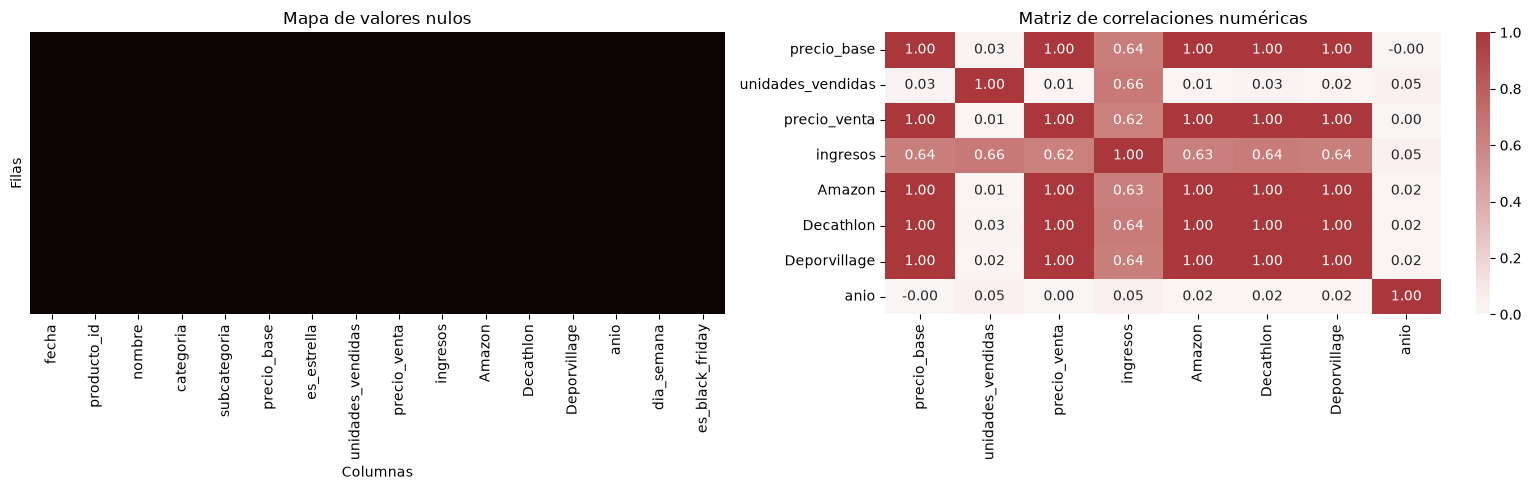

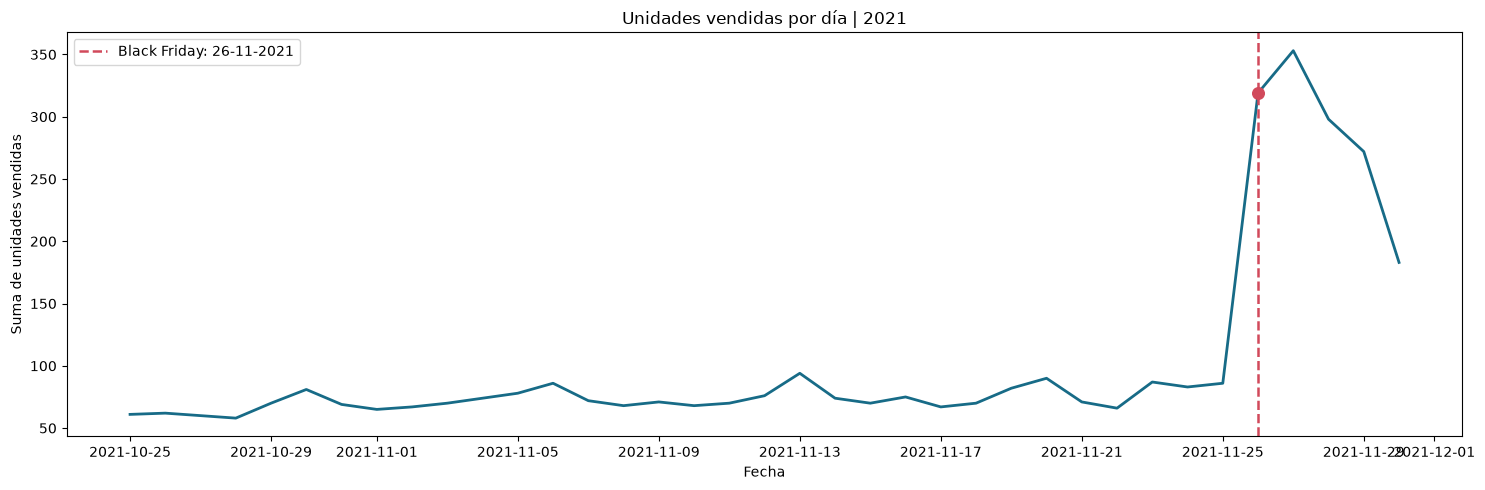

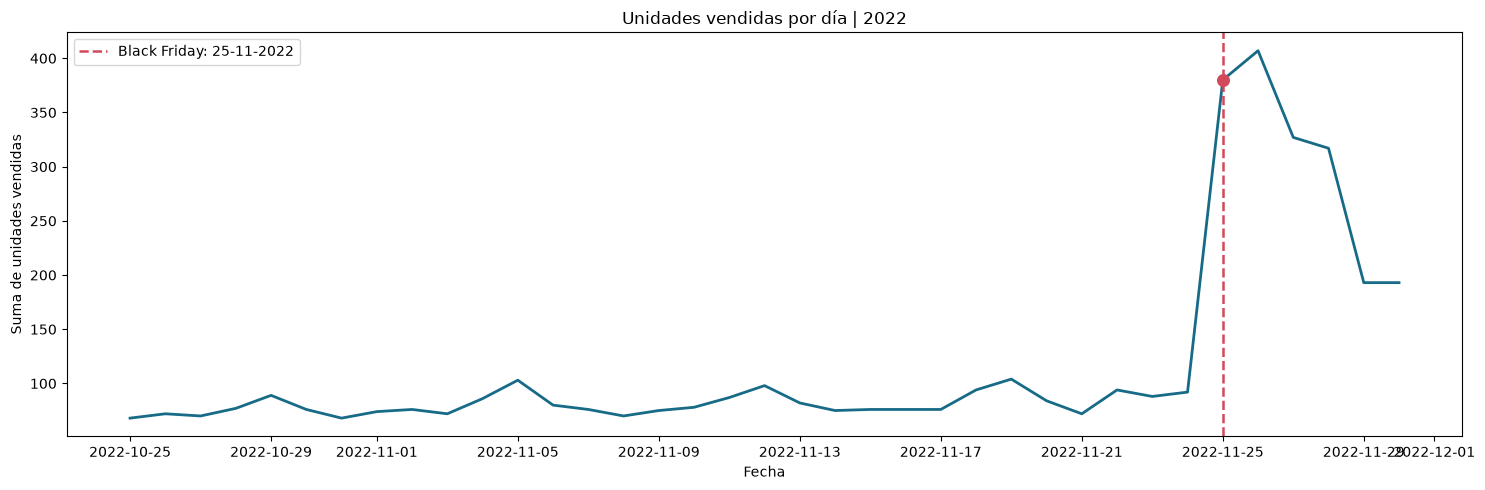

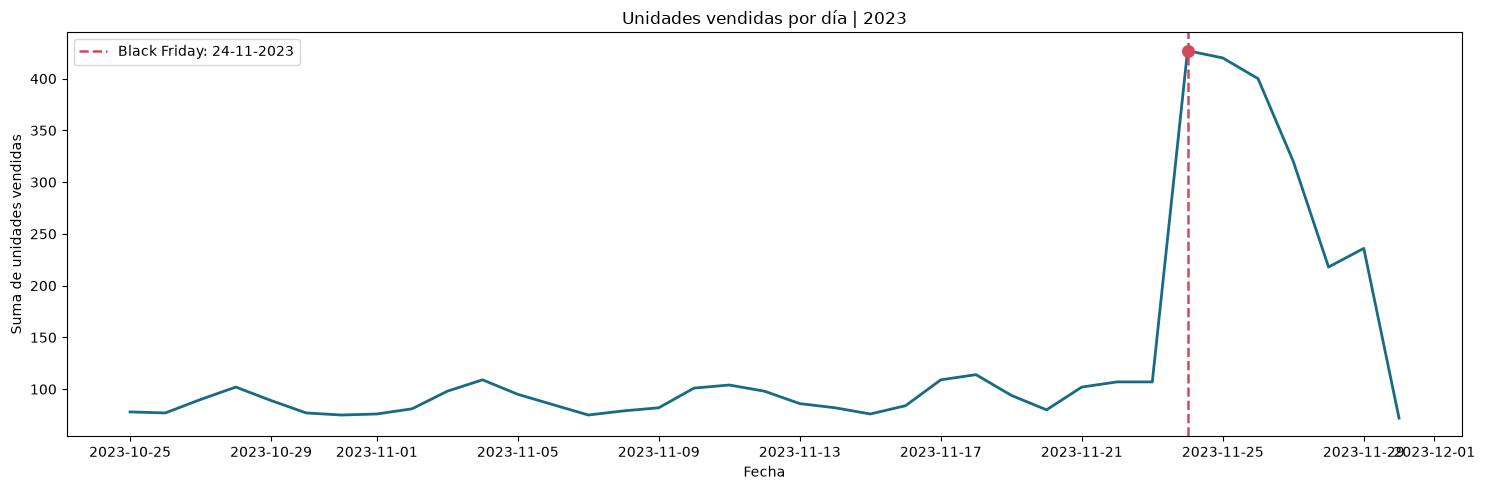

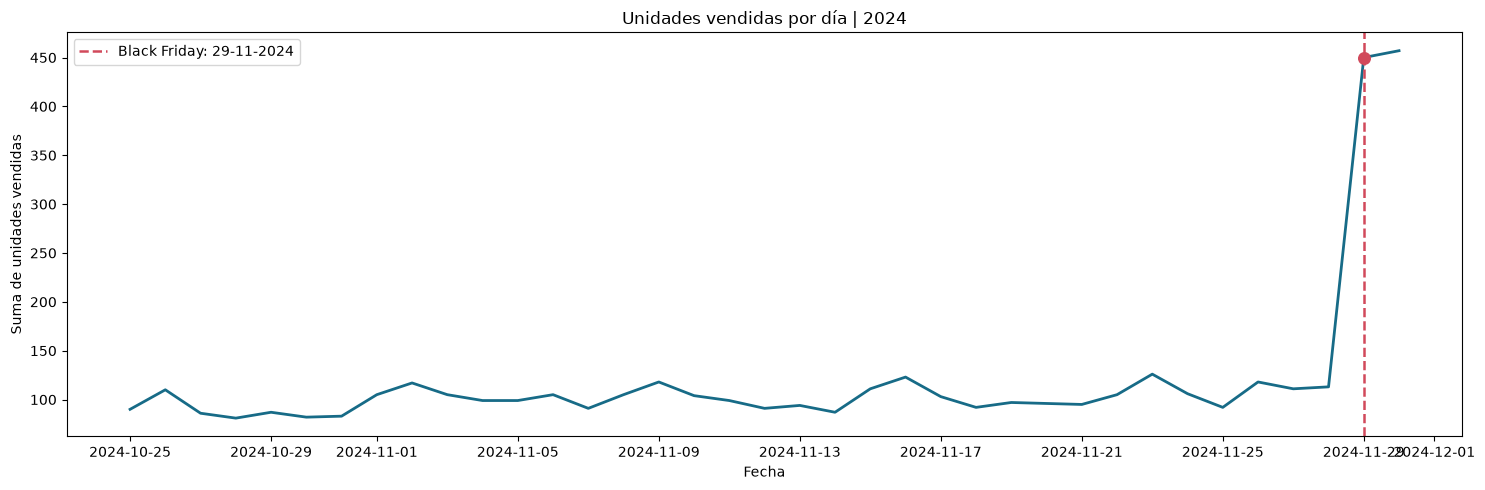

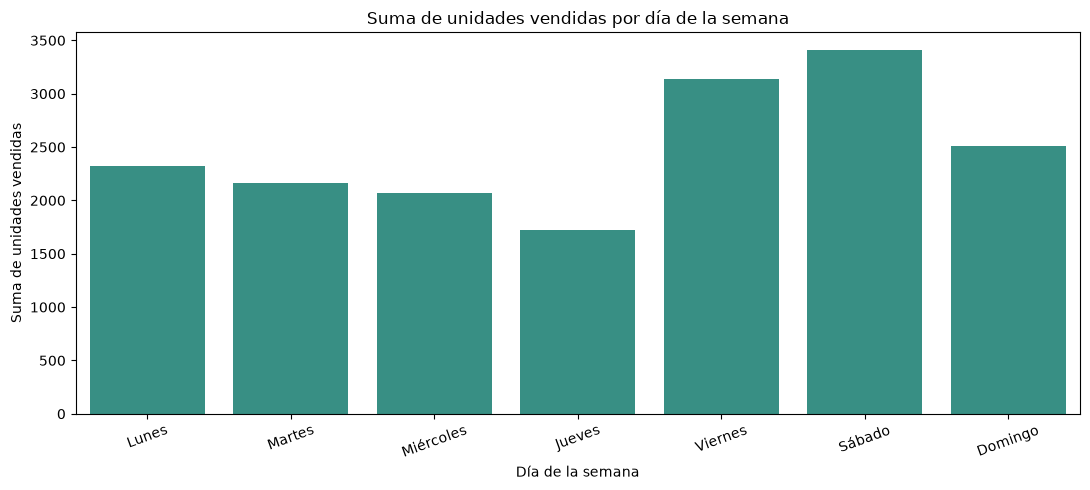

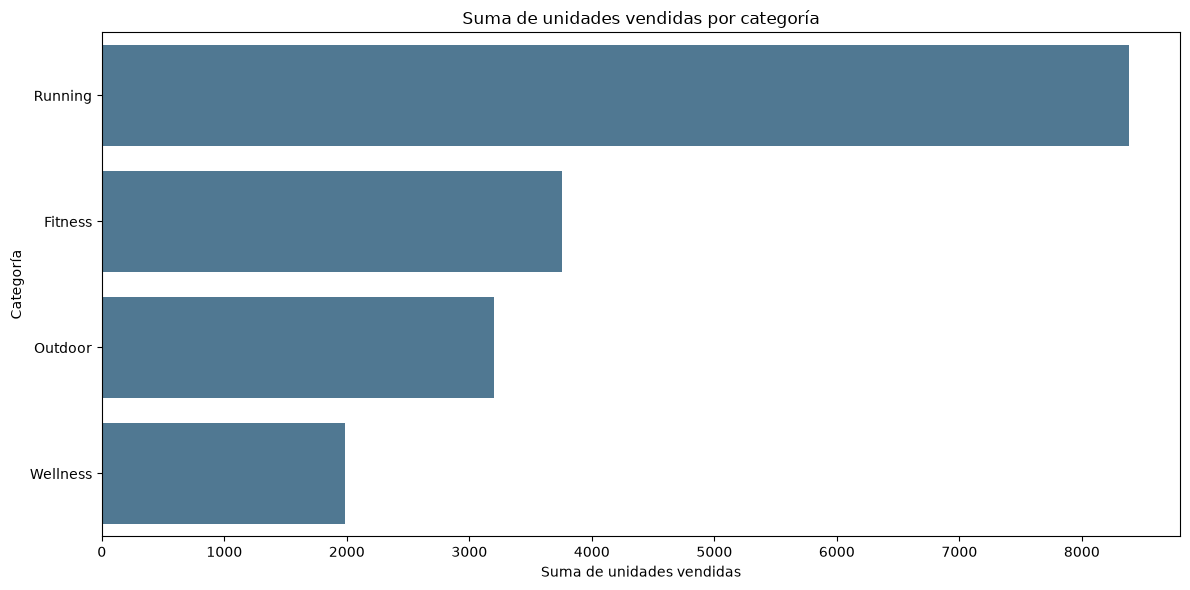

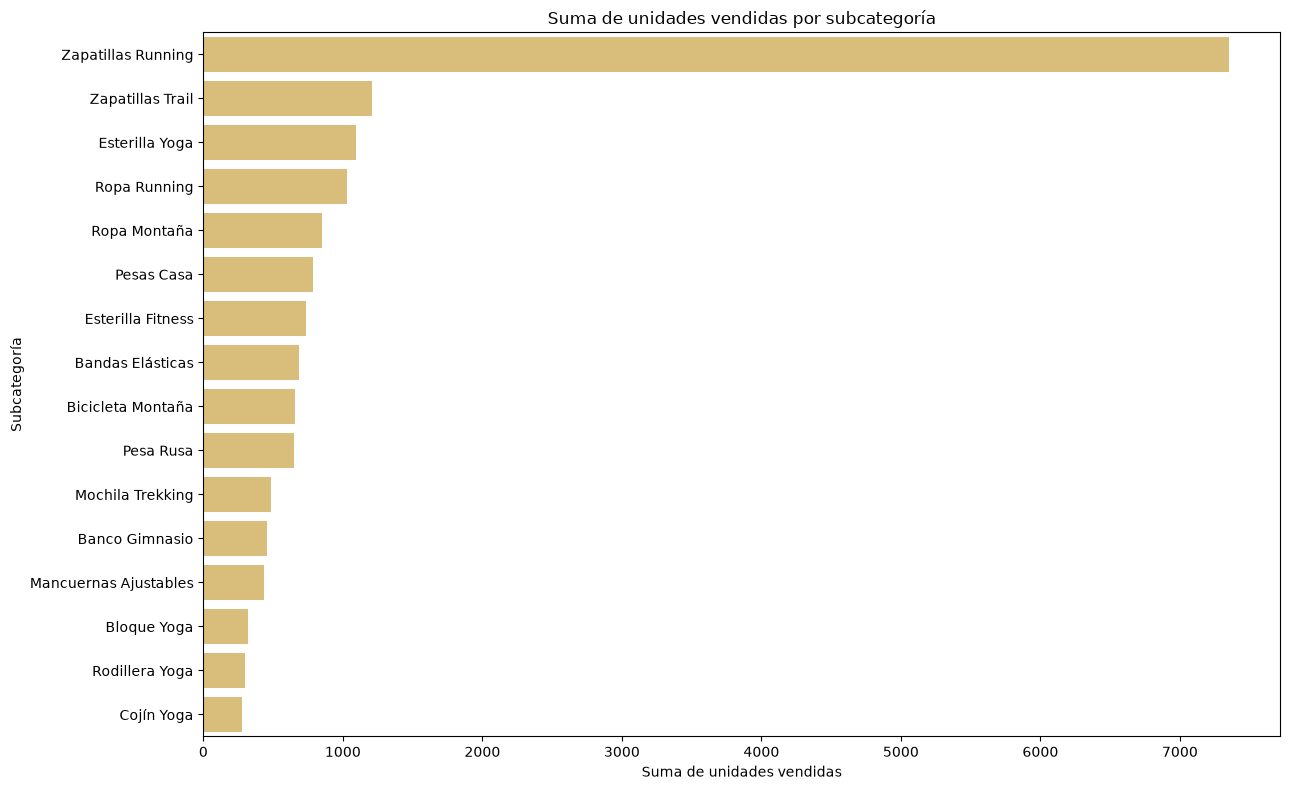

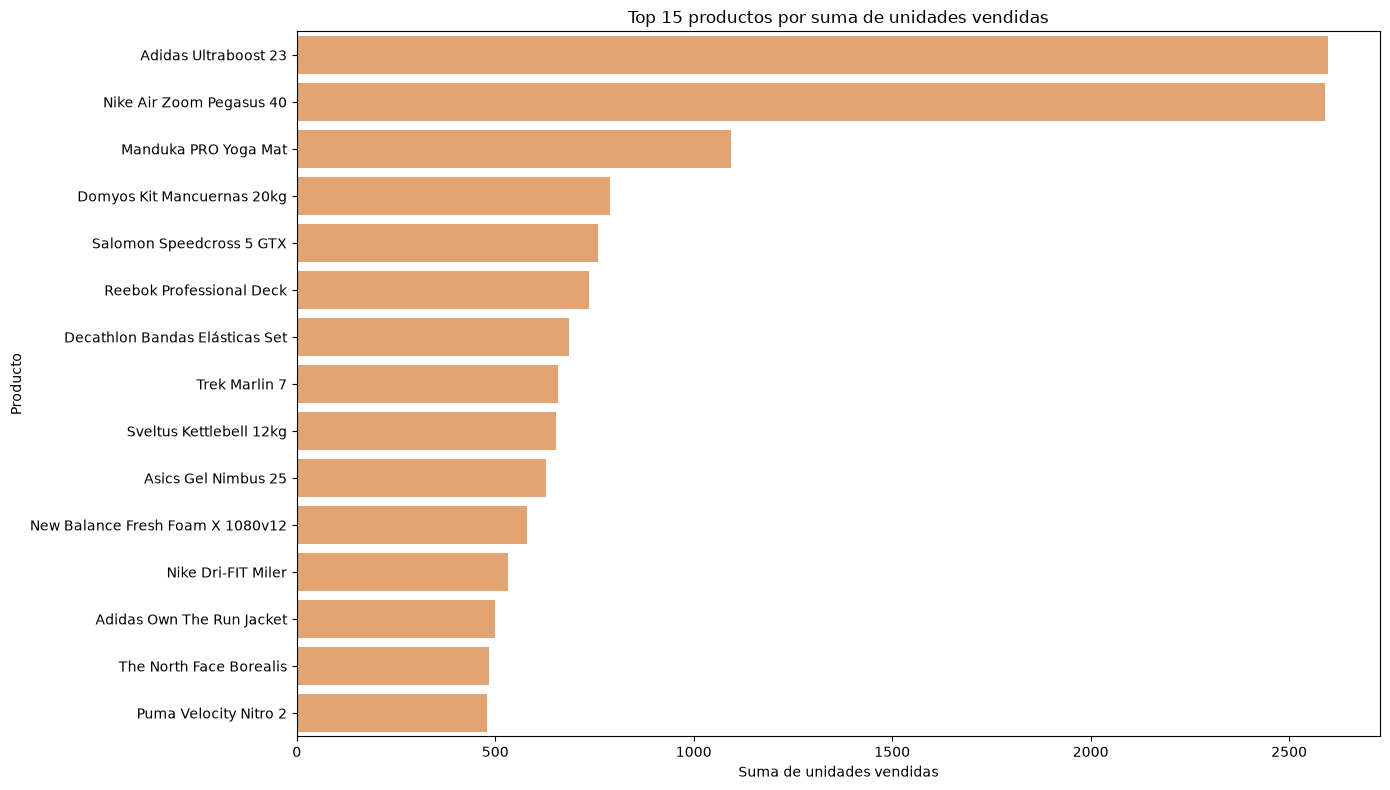

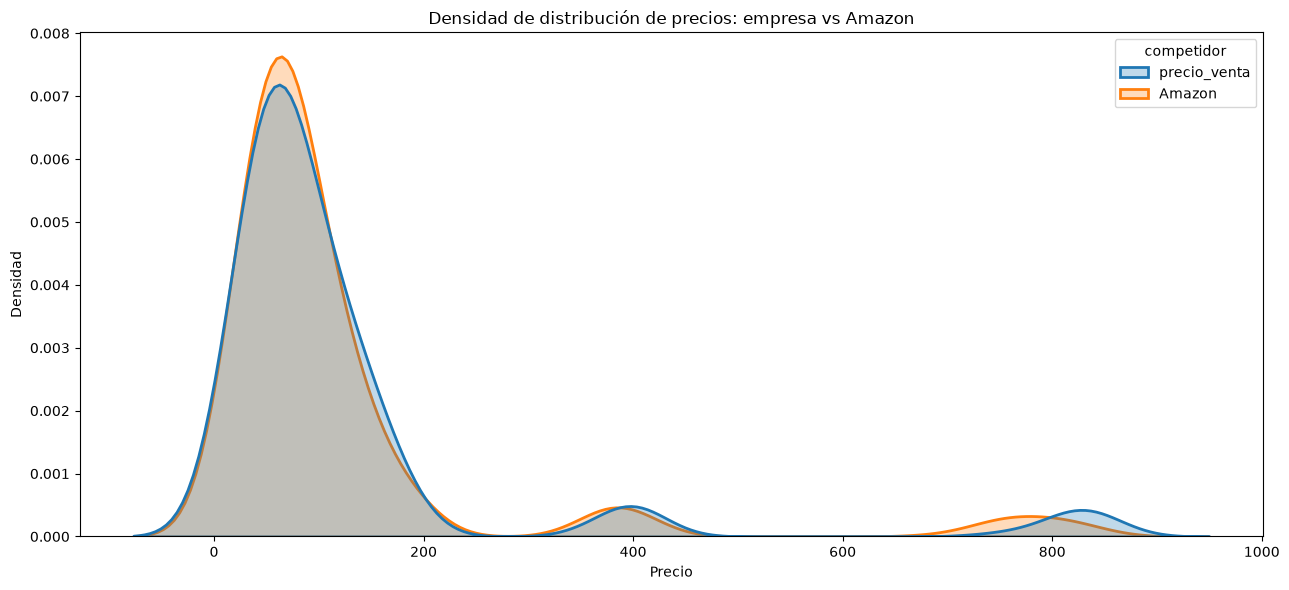

Resumen de precios:
               count    mean     std    min    25%    50%     75%     max
competidor                                                               
Amazon        3552.0  118.62  156.10  16.85  47.12  73.18  114.34  858.35
precio_venta  3552.0  121.82  164.02  19.00  47.21  71.81  118.22  854.22


In [4]:
# ================= PREPARACION PARA EL ANALISIS EXPLORATORIO =================
# Se trabaja sobre el DataFrame integrado df creado en la celda anterior.
df_eda = df.copy()
df_eda["fecha"] = pd.to_datetime(df_eda["fecha"], errors="coerce")
df_eda["unidades_vendidas"] = pd.to_numeric(df_eda["unidades_vendidas"], errors="coerce")
df_eda["precio_venta"] = pd.to_numeric(df_eda["precio_venta"], errors="coerce")
df_eda["Amazon"] = pd.to_numeric(df_eda["Amazon"], errors="coerce")
df_eda["anio"] = df_eda["fecha"].dt.year
df_eda["dia_semana"] = df_eda["fecha"].dt.day_name()

# El Black Friday es el ultimo viernes de noviembre de cada año.
noviembres = df_eda["fecha"].dt.to_period("M") == df_eda["fecha"].dt.to_period("M").map(
    lambda periodo: f"{periodo.year}-11"
)
# Se calculan las fechas de Black Friday a partir del calendario observado.
black_fridays = {}
for anio in sorted(df_eda["anio"].dropna().unique()):
    fechas_noviembre = pd.date_range(f"{int(anio)}-11-01", f"{int(anio)}-11-30", freq="D")
    black_fridays[int(anio)] = fechas_noviembre[fechas_noviembre.dayofweek == 4].max()

df_eda["es_black_friday"] = df_eda["fecha"].map(
    lambda fecha: fecha.normalize() in set(black_fridays.values()) if pd.notna(fecha) else False
)

print(f"Filas analizadas: {len(df_eda):,}")
print(f"Periodo: {df_eda['fecha'].min().date()} a {df_eda['fecha'].max().date()}")
print(f"Años disponibles: {sorted(df_eda['anio'].dropna().unique().astype(int).tolist())}")
print(f"Registros de Black Friday: {int(df_eda['es_black_friday'].sum()):,}")
print("Fechas Black Friday:", [fecha.strftime("%Y-%m-%d") for fecha in black_fridays.values()])

# ================= RESUMEN EXPLORATORIO DEL DATAFRAME =================
print("DIMENSIONES:", df_eda.shape)
print("\nTIPOS DE DATOS:")
print(df_eda.dtypes.to_string())
print("\nVALORES NULOS:")
print(df_eda.isna().sum().sort_values(ascending=False).to_string())
print("\nDUPLICADOS:", int(df_eda.duplicated().sum()))
print("\nESTADISTICOS NUMERICOS:")
print(df_eda.select_dtypes(include=np.number).describe().T.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(df_eda.isna(), cbar=False, yticklabels=False, cmap="mako", ax=axes[0])
axes[0].set_title("Mapa de valores nulos")
axes[0].set_xlabel("Columnas")
axes[0].set_ylabel("Filas")

correlaciones = df_eda.select_dtypes(include=np.number).corr()
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Matriz de correlaciones numéricas")
plt.tight_layout()
plt.show()

# ================= SUMA DE UNIDADES VENDIDAS POR AÑO =================
# Se genera un gráfico independiente para cada año y se marca su Black Friday.
for anio in sorted(df_eda["anio"].dropna().unique()):
    datos_anio = (
        df_eda[df_eda["anio"] == anio]
        .groupby("fecha", as_index=False)["unidades_vendidas"]
        .sum()
        .sort_values("fecha")
    )
    fecha_bf = black_fridays.get(int(anio))

    plt.figure(figsize=(15, 5))
    sns.lineplot(data=datos_anio, x="fecha", y="unidades_vendidas", color="#176b87", linewidth=2)
    if fecha_bf is not None and fecha_bf >= datos_anio["fecha"].min() and fecha_bf <= datos_anio["fecha"].max():
        unidades_bf = datos_anio.loc[datos_anio["fecha"] == fecha_bf, "unidades_vendidas"]
        plt.axvline(fecha_bf, color="#d1495b", linestyle="--", linewidth=1.8, label=f"Black Friday: {fecha_bf:%d-%m-%Y}")
        if not unidades_bf.empty:
            plt.scatter(fecha_bf, unidades_bf.iloc[0], color="#d1495b", s=70, zorder=3)
    plt.title(f"Unidades vendidas por día | {int(anio)}")
    plt.xlabel("Fecha")
    plt.ylabel("Suma de unidades vendidas")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ================= UNIDADES VENDIDAS POR DIA DE LA SEMANA =================
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
datos_dia = (
    df_eda.groupby("dia_semana", as_index=False)["unidades_vendidas"]
    .sum()
    .set_index("dia_semana")
    .reindex(orden_dias)
    .reset_index()
)
datos_dia["dia_semana"] = datos_dia["dia_semana"].map({
    "Monday": "Lunes", "Tuesday": "Martes", "Wednesday": "Miércoles",
    "Thursday": "Jueves", "Friday": "Viernes", "Saturday": "Sábado", "Sunday": "Domingo"
})
plt.figure(figsize=(11, 5))
sns.barplot(data=datos_dia, x="dia_semana", y="unidades_vendidas", color="#2a9d8f")
plt.title("Suma de unidades vendidas por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Suma de unidades vendidas")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# ================= UNIDADES VENDIDAS POR CATEGORIA =================
datos_categoria = (
    df_eda.groupby("categoria", as_index=False)["unidades_vendidas"]
    .sum()
    .sort_values("unidades_vendidas", ascending=False)
)
plt.figure(figsize=(12, 6))
sns.barplot(data=datos_categoria, x="unidades_vendidas", y="categoria", color="#457b9d")
plt.title("Suma de unidades vendidas por categoría")
plt.xlabel("Suma de unidades vendidas")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

# ================= UNIDADES VENDIDAS POR SUBCATEGORIA =================
datos_subcategoria = (
    df_eda.groupby("subcategoria", as_index=False)["unidades_vendidas"]
    .sum()
    .sort_values("unidades_vendidas", ascending=False)
)
plt.figure(figsize=(13, 8))
sns.barplot(data=datos_subcategoria, x="unidades_vendidas", y="subcategoria", color="#e9c46a")
plt.title("Suma de unidades vendidas por subcategoría")
plt.xlabel("Suma de unidades vendidas")
plt.ylabel("Subcategoría")
plt.tight_layout()
plt.show()

# ================= TOP PRODUCTOS =================
top_n = 15
datos_top_productos = (
    df_eda.groupby(["producto_id", "nombre"], as_index=False)["unidades_vendidas"]
    .sum()
    .sort_values("unidades_vendidas", ascending=False)
    .head(top_n)
)
datos_top_productos["producto"] = datos_top_productos["nombre"].str.slice(0, 38)
plt.figure(figsize=(14, 8))
sns.barplot(data=datos_top_productos, x="unidades_vendidas", y="producto", color="#f4a261")
plt.title(f"Top {top_n} productos por suma de unidades vendidas")
plt.xlabel("Suma de unidades vendidas")
plt.ylabel("Producto")
plt.tight_layout()
plt.show()

# ================= DENSIDAD DE PRECIOS: EMPRESA VS AMAZON =================
precios = df_eda[["precio_venta", "Amazon"]].melt(
    var_name="competidor", value_name="precio"
).dropna()
precios = precios[precios["precio"] >= 0]
plt.figure(figsize=(13, 6))
sns.kdeplot(
    data=precios, x="precio", hue="competidor", common_norm=False,
    fill=True, alpha=0.28, linewidth=2, warn_singular=False
)
plt.title("Densidad de distribución de precios: empresa vs Amazon")
plt.xlabel("Precio")
plt.ylabel("Densidad")
plt.tight_layout()
plt.show()

print("Resumen de precios:")
print(precios.groupby("competidor")["precio"].describe().round(2).to_string())

In [5]:
# ================= VARIABLES TEMPORALES Y DE CALENDARIO =================
# Variables basicas para capturar estacionalidad, patrones semanales y cierres de periodo.
df_eda["anio"] = df_eda["fecha"].dt.year.astype("Int64")
df_eda["mes"] = df_eda["fecha"].dt.month.astype("Int64")
df_eda["trimestre"] = df_eda["fecha"].dt.quarter.astype("Int64")
df_eda["semana_anio"] = df_eda["fecha"].dt.isocalendar().week.astype("Int64")
df_eda["dia_mes"] = df_eda["fecha"].dt.day.astype("Int64")
df_eda["dia_anio"] = df_eda["fecha"].dt.dayofyear.astype("Int64")
df_eda["dia_semana_num"] = df_eda["fecha"].dt.dayofweek.astype("Int64")
df_eda["es_fin_de_semana"] = df_eda["dia_semana_num"].ge(5).fillna(False)
df_eda["es_inicio_mes"] = df_eda["fecha"].dt.is_month_start.fillna(False)
df_eda["es_fin_mes"] = df_eda["fecha"].dt.is_month_end.fillna(False)
df_eda["es_inicio_trimestre"] = df_eda["fecha"].dt.is_quarter_start.fillna(False)
df_eda["es_fin_trimestre"] = df_eda["fecha"].dt.is_quarter_end.fillna(False)

# Festivos oficiales de Espana para todos los años presentes en los datos.
anios_datos = df_eda["anio"].dropna().astype(int).unique().tolist()
festivos_espana = holidays.Spain(years=anios_datos, language="es")
nombres_festivos = df_eda["fecha"].map(
    lambda fecha: festivos_espana.get(fecha.date()) if pd.notna(fecha) else np.nan
)
df_eda["es_festivo"] = nombres_festivos.notna()
df_eda["nombre_festivo"] = nombres_festivos
df_eda["es_dia_laborable"] = (~df_eda["es_fin_de_semana"] & ~df_eda["es_festivo"]).fillna(False)

# Black Friday es el ultimo viernes de noviembre y Cyber Monday el lunes siguiente.
black_fridays = {}
cyber_mondays = {}
for anio in anios_datos:
    fechas_noviembre = pd.date_range(f"{anio}-11-01", f"{anio}-11-30", freq="D")
    black_fridays[anio] = fechas_noviembre[fechas_noviembre.dayofweek == 4].max()
    cyber_mondays[anio] = black_fridays[anio] + pd.Timedelta(days=3)

fechas_black_friday = {pd.Timestamp(fecha).normalize() for fecha in black_fridays.values()}
fechas_cyber_monday = {pd.Timestamp(fecha).normalize() for fecha in cyber_mondays.values()}
df_eda["es_black_friday"] = df_eda["fecha"].map(
    lambda fecha: fecha.normalize() in fechas_black_friday if pd.notna(fecha) else False
)
df_eda["es_cyber_monday"] = df_eda["fecha"].map(
    lambda fecha: fecha.normalize() in fechas_cyber_monday if pd.notna(fecha) else False
)
df_eda["dias_hasta_black_friday"] = df_eda["fecha"].map(
    lambda fecha: (black_fridays.get(int(fecha.year)) - fecha).days
    if pd.notna(fecha) and int(fecha.year) in black_fridays else np.nan
)
df_eda["dias_desde_black_friday"] = -df_eda["dias_hasta_black_friday"]

print(f"Variables temporales creadas: {len(df_eda.columns)} columnas totales")
print(f"Registros de festivos: {int(df_eda['es_festivo'].sum()):,}")
print(f"Registros de Black Friday: {int(df_eda['es_black_friday'].sum()):,}")
print(f"Registros de Cyber Monday: {int(df_eda['es_cyber_monday'].sum()):,}")
print("Fechas Black Friday:", [fecha.strftime("%Y-%m-%d") for fecha in black_fridays.values()])
print("Fechas Cyber Monday:", [fecha.strftime("%Y-%m-%d") for fecha in cyber_mondays.values()])

Variables temporales creadas: 33 columnas totales
Registros de festivos: 96
Registros de Black Friday: 96
Registros de Cyber Monday: 72
Fechas Black Friday: ['2021-11-26', '2022-11-25', '2023-11-24', '2024-11-29']
Fechas Cyber Monday: ['2021-11-29', '2022-11-28', '2023-11-27', '2024-12-02']


In [17]:
# ================= RESUMEN DE VENTAS POR PRODUCTO =================
# Los ingresos se calculan como unidades vendidas por precio de venta.
df_productos = df_eda.copy()
df_productos["ingresos_venta"] = (
    df_productos["unidades_vendidas"] * df_productos["precio_venta"]
)

# Resumen general de unidades, ingresos y precio medio por producto.
resumen_productos = (
    df_productos.groupby(["producto_id", "nombre"], as_index=False)
    .agg(
        unidades_vendidas=("unidades_vendidas", "sum"),
        precio_venta_medio=("precio_venta", "mean"),
        ingresos_totales=("ingresos_venta", "sum"),
    )
)

# Se consideran top productos los 15 con mayor cantidad total de unidades vendidas.
top_n_productos = 15
ids_top_productos = set(
    resumen_productos.nlargest(top_n_productos, "unidades_vendidas")["producto_id"]
)
resumen_productos["es_top_producto"] = resumen_productos["producto_id"].isin(ids_top_productos)

# Encontrar el trimestre con más unidades vendidas para cada producto.
ventas_por_trimestre = (
    df_productos.dropna(subset=["anio", "trimestre"])
    .groupby(["producto_id", "anio", "trimestre"], as_index=False)["unidades_vendidas"]
    .sum()
    .sort_values(
        ["producto_id", "unidades_vendidas", "anio", "trimestre"],
        ascending=[True, False, True, True],
    )
    .drop_duplicates("producto_id")
    .rename(
        columns={
            "anio": "anio_mayor_venta",
            "trimestre": "trimestre_mayor_venta",
            "unidades_vendidas": "unidades_trimestre_mayor_venta",
        }
    )
)

# Encontrar el año con más unidades vendidas para cada producto.
ventas_por_anio = (
    df_productos.dropna(subset=["anio"])
    .groupby(["producto_id", "anio"], as_index=False)["unidades_vendidas"]
    .sum()
    .sort_values(
        ["producto_id", "unidades_vendidas", "anio"],
        ascending=[True, False, True],
    )
    .drop_duplicates("producto_id")
    .rename(
        columns={
            "anio": "anio_mayor_venta",
            "unidades_vendidas": "unidades_anio_mayor_venta",
        }
    )
)

# Unir el periodo de mayor venta al resumen final.
resumen_productos = resumen_productos.merge(
    ventas_por_trimestre[
        [
            "producto_id",
            "trimestre_mayor_venta",
            "anio_mayor_venta",
            "unidades_trimestre_mayor_venta",
        ]
    ],
    on="producto_id",
    how="left",
)
resumen_productos = resumen_productos.merge(
    ventas_por_anio[["producto_id", "unidades_anio_mayor_venta"]],
    on="producto_id",
    how="left",
)

resumen_productos = resumen_productos.sort_values(
    "ingresos_totales", ascending=False
).reset_index(drop=True)

print("RESUMEN DE VENTAS POR PRODUCTO")
print(f"Productos analizados: {len(resumen_productos):,}")
print(f"Productos top: {int(resumen_productos['es_top_producto'].sum()):,}")
print(
    resumen_productos[
        [
            "producto_id",
            "nombre",
            "es_top_producto",
            "precio_venta_medio",
            "unidades_vendidas",
            "ingresos_totales",
            "trimestre_mayor_venta",
            "anio_mayor_venta",
            "unidades_trimestre_mayor_venta",
            "unidades_anio_mayor_venta",
        ]
    ].head(20).to_string(index=False)
)

RESUMEN DE VENTAS POR PRODUCTO
Productos analizados: 24
Productos top: 15
producto_id                           nombre  es_top_producto  precio_venta_medio  unidades_vendidas  ingresos_totales  trimestre_mayor_venta  anio_mayor_venta  unidades_trimestre_mayor_venta  unidades_anio_mayor_venta
   PROD_016                    Trek Marlin 7             True          821.394122                657         530080.19                      4              2023                             183                        183
   PROD_002             Adidas Ultraboost 23             True          133.194662               2599         334963.48                      4              2023                             774                        774
   PROD_001         Nike Air Zoom Pegasus 40             True          113.327162               2590         284878.33                      4              2023                             716                        716
   PROD_009           Bowflex SelectTech 552      

In [23]:
# ================= LAGS Y MEDIA MOVIL DE UNIDADES VENDIDAS =================
# Se trabaja con una copia para conservar df_eda completo y poder comparar los resultados.
df_lags = df_eda.copy()
df_lags = df_lags.sort_values(["producto_id", "anio", "fecha"]).reset_index(drop=True)

# Los lags se calculan por producto y año: cada año comienza sin arrastrar datos del anterior.
grupo_producto_anio = df_lags.groupby(["producto_id", "anio"], sort=False)["unidades_vendidas"]
for dias in range(1, 8):
    df_lags[f"unidades_lag_{dias}"] = grupo_producto_anio.shift(dias)

# La media móvil usa los siete días anteriores dentro del mismo producto y año.
df_lags["media_movil_7_dias"] = (
    df_lags.groupby(["producto_id", "anio"], sort=False)["unidades_vendidas"]
    .transform(lambda serie: serie.shift(1).rolling(window=7, min_periods=7).mean())
)

variables_lag = [f"unidades_lag_{dias}" for dias in range(1, 8)]
variables_temporales_nuevas = variables_lag + ["media_movil_7_dias"]
filas_antes_limpieza = len(df_lags)
filas_con_nulos_lag = int(df_lags[variables_temporales_nuevas].isna().any(axis=1).sum())

# Se eliminan las filas que no tienen historial suficiente para todas las variables nuevas.
df_lags = df_lags.dropna(subset=variables_temporales_nuevas).reset_index(drop=True)
filas_eliminadas = filas_antes_limpieza - len(df_lags)

print("RESUMEN DE LAGS Y MEDIA MOVIL")
print(f"Filas antes de eliminar nulos: {filas_antes_limpieza:,}")
print(f"Filas con algun nulo en variables nuevas: {filas_con_nulos_lag:,}")
print(f"Filas eliminadas: {filas_eliminadas:,}")
print(f"Filas finales: {len(df_lags):,}")
print("Nulos restantes en variables nuevas:")
print(df_lags[variables_temporales_nuevas].isna().sum().to_string())

# Para mostrar cada producto una sola vez, se selecciona su ultima fecha disponible.
productos_una_linea = (
    df_lags.sort_values(["producto_id", "fecha"])
    .groupby("producto_id", as_index=False)
    .tail(1)
    .sort_values("producto_id")
)

# Se redondea solo la copia de salida; df_lags conserva la precision original.
productos_salida = productos_una_linea[
    [
        "producto_id",
        "nombre",
        "fecha",
        "anio",
        "unidades_vendidas",
        *variables_lag,
        "media_movil_7_dias",
    ]
].copy()
productos_salida["media_movil_7_dias"] = (
    productos_salida["media_movil_7_dias"].round().astype(int)
)

print("\nULTIMA OBSERVACION DISPONIBLE DE CADA PRODUCTO")
print(productos_salida.to_string(index=False))

RESUMEN DE LAGS Y MEDIA MOVIL
Filas antes de eliminar nulos: 3,552
Filas con algun nulo en variables nuevas: 672
Filas eliminadas: 672
Filas finales: 2,880
Nulos restantes en variables nuevas:
unidades_lag_1        0
unidades_lag_2        0
unidades_lag_3        0
unidades_lag_4        0
unidades_lag_5        0
unidades_lag_6        0
unidades_lag_7        0
media_movil_7_dias    0

ULTIMA OBSERVACION DISPONIBLE DE CADA PRODUCTO
producto_id                           nombre      fecha  anio  unidades_vendidas  unidades_lag_1  unidades_lag_2  unidades_lag_3  unidades_lag_4  unidades_lag_5  unidades_lag_6  unidades_lag_7  media_movil_7_dias
   PROD_001         Nike Air Zoom Pegasus 40 2024-11-30  2024                 80            66.0            15.0            13.0            18.0            12.0            16.0            16.0                  22
   PROD_002             Adidas Ultraboost 23 2024-11-30  2024                 65            68.0            18.0            16.0            1